[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ErvinasE/commit-message-generator/blob/main/1.3/Telco_NN.ipynb)

# Telco klientų nutekėjimas: neuroninis tinklas

Šis sąsiuvinis yra perdarytas dėstytojo A. Laukaičio sąsiuvinis `AdventureWorksDW_NN.ipynb`.
Technika ta pati (Keras neuroninis tinklas su požymių apdorojimo sluoksniais), tačiau duomenys tie patys kaip
sąsiuvinyje `Telco_Decision_Forests.ipynb`: Kaggle [Telco Customer Churn](https://www.kaggle.com/datasets/blastchar/telco-customer-churn).
Taip galime tiesiogiai palyginti sprendimų mišką ir neuroninį tinklą.

| | Originalas | Šis sąsiuvinis |
|---|---|---|
| Duomenys | AdventureWorks DW `vTargetMail` (18 484 klientai) | Telco Customer Churn (7 043 klientai) |
| Klausimas | Ar klientas nupirks dviratį? | Ar klientas išeis? |
| Požymiai | 6 kategoriniai + 1 sveikasis kategorinis + 5 skaitiniai | 8 kategoriniai + 1 sveikasis kategorinis + 3 skaitiniai |
| Tinklas | 64 → 32 → 1 neuronas | toks pat |

---
# 1 žingsnis. Iš CSV failo į tris lenteles: mokymo, validavimo ir testavimo

## 1.1 Įkeliame duomenis

Colab'e failas parsisiunčiamas iš GitHub, o lokaliai imamas iš aplanko `data/`.

In [1]:
import os
import pandas as pd

GITHUB_BRANCH = 'main'
DATA_URL = f'https://raw.githubusercontent.com/ErvinasE/commit-message-generator/{GITHUB_BRANCH}/1.3/data/'
FILE_NAME = 'WA_Fn-UseC_-Telco-Customer-Churn.csv'

data_dir = 'data/' if os.path.exists('data/' + FILE_NAME) else DATA_URL
df_all_col = pd.read_csv(data_dir + FILE_NAME)
print('Lentelėje yra {} eilučių ir {} stulpelių.'.format(df_all_col.shape[0], df_all_col.shape[1]))

Lentelėje yra 7043 eilučių ir 21 stulpelių.


## 1.2 Peržiūrime vieną eilutę

Stulpelių reikšmės aprašytos sąsiuvinyje `Telco_Decision_Forests.ipynb` (1.2 skyrius).

In [2]:
print(df_all_col.iloc[10])

customerID              9763-GRSKD
gender                        Male
SeniorCitizen                    0
Partner                        Yes
Dependents                     Yes
tenure                          13
PhoneService                   Yes
MultipleLines                   No
InternetService                DSL
OnlineSecurity                 Yes
OnlineBackup                    No
DeviceProtection                No
TechSupport                     No
StreamingTV                     No
StreamingMovies                 No
Contract            Month-to-month
PaperlessBilling               Yes
PaymentMethod         Mailed check
MonthlyCharges               49.95
TotalCharges                587.45
Churn                           No
Name: 10, dtype: object


## 1.3 Pašaliname nereikalingus stulpelius ir sutvarkome duomenis

Tas pats paruošimas kaip sprendimų miško sąsiuvinyje: paliekame 12 požymių, `TotalCharges` paverčiame skaičiumi
(11 tuščių reikšmių pakeičiame 0), `Churn` paverčiame `target` (1 = išėjo, 0 = liko).

In [3]:
df = df_all_col.copy()

df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce').fillna(0)
df['target'] = (df['Churn'] == 'Yes').astype(int)

df.drop(columns=['customerID', 'Churn', 'MultipleLines', 'OnlineSecurity', 'OnlineBackup',
                 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies'], inplace=True)

Neuroniniam tinklui svarbūs stulpelių **tipai**: tekstiniai (`str`) bus koduojami kaip kategorijos,
sveikieji (`int64`) ir realieji (`float64`) skaičiai bus normalizuojami. `SeniorCitizen` yra skaičius 0/1,
bet iš tikrųjų tai kategorija, todėl jį koduosime kaip kategoriją (kaip `HouseOwnerFlag` originale).

In [4]:
print(df.iloc[0])
print('---------------')
print(df.dtypes)

gender                        Female
SeniorCitizen                      0
Partner                          Yes
Dependents                        No
tenure                             1
PhoneService                      No
InternetService                  DSL
Contract              Month-to-month
PaperlessBilling                 Yes
PaymentMethod       Electronic check
MonthlyCharges                 29.85
TotalCharges                   29.85
target                             0
Name: 0, dtype: object
---------------
gender                  str
SeniorCitizen         int64
Partner                 str
Dependents              str
tenure                int64
PhoneService            str
InternetService         str
Contract                str
PaperlessBilling        str
PaymentMethod           str
MonthlyCharges      float64
TotalCharges        float64
target                int64
dtype: object


## 1.4 Padaliname į mokymo, validavimo ir testavimo aibes

* **mokymo** aibė (80 %): su ja tinklas mokosi;
* **validavimo** aibė (10 %): kiekvienos epochos pabaigoje tikriname, ar tinklas nepersimoko
  (*overfitting*: gerai atsimena mokymo duomenis, bet blogai veikia su naujais);
* **testavimo** aibė (10 %): galutinis įvertinimas su duomenimis, kurių tinklas niekada nematė.

Taip pat apskaičiuojame **bazinį lygį**: tikslumą, kurį gautume visada spėdami „klientas lieka“.

In [5]:
df = df.sample(frac=1, random_state=42)  # atsitiktinai sumaišome eilutes
n = len(df)
train = df.iloc[:int(0.8 * n)]
validation = df.iloc[int(0.8 * n):int(0.9 * n)]
test = df.iloc[int(0.9 * n):]
print(len(train), 'mokymo pavyzdžiai')
print(len(validation), 'validavimo pavyzdžiai')
print(len(test), 'testavimo pavyzdžiai')

baseline = (test['target'] == 0).mean()
print('Bazinis lygis testavimo aibėje (visada „lieka“): {:.4f}'.format(baseline))

5634 mokymo pavyzdžiai
704 validavimo pavyzdžiai
705 testavimo pavyzdžiai
Bazinis lygis testavimo aibėje (visada „lieka“): 0.7574


---
# 2 žingsnis. Iš `pandas` lentelės į TensorFlow duomenų rinkinį

`df_to_dataset` paverčia lentelę į `tf.data.Dataset`: atskiria tikslą (`target`) nuo požymių,
kiekvieną stulpelį paverčia atskiru masyvu (žodyno raktas = stulpelio pavadinimas), sumaišo eilutes ir
suskirsto jas į paketus (*batch*) po 256 eilutes. Tinklas svorius atnaujina po kiekvieno paketo.

**Pataisyta klaida:** originale žodynas buvo kuriamas iš `dataframe.items()` (pradinės lentelės, kurioje
`target` dar yra), todėl `target` pateko tarp tinklo įėjimų. Tinklas jo nenaudojo (tokio įėjimo nėra),
tik mokymo metu rodė ilgą įspėjimą. Čia naudojame `df.items()`, iš kurios `target` jau išimtas.

`keras.utils.set_random_seed(42)` užfiksuoja atsitiktinius skaičius (pradinius svorius, sumaišymą, *dropout*),
todėl rezultatai atkartojami.

In [6]:
import numpy as np
import tensorflow as tf
import keras

keras.utils.set_random_seed(42)


def df_to_dataset(dataframe, shuffle=True, batch_size=32):
  df = dataframe.copy()
  labels = df.pop('target')
  df = {key: value.to_numpy()[:, tf.newaxis] for key, value in df.items()}

  ds = tf.data.Dataset.from_tensor_slices((dict(df), labels))
  if shuffle:
    ds = ds.shuffle(buffer_size=len(dataframe))
  ds = ds.batch(batch_size)
  ds = ds.prefetch(batch_size)
  return ds


batch_size = 256
train_ds = df_to_dataset(train, batch_size=batch_size)
validation_ds = df_to_dataset(validation, shuffle=False, batch_size=batch_size)
test_ds = df_to_dataset(test, shuffle=False, batch_size=batch_size)

---
# 3 žingsnis. Modelis

Tinklas turi 12 įėjimų (po vieną kiekvienam požymiui). Kiekvienas įėjimas pirmiausia paverčiamas skaičiais,
tada visi skaičiai sujungiami į vieną vektorių ir paduodami tankiesiems (*Dense*) sluoksniams.

In [7]:
all_inputs = {}
encoded_features = []

## Kategoriniai stulpeliai

`get_category_encoding_layer` sukuria du sluoksnius:
1. `StringLookup` (tekstui) arba `IntegerLookup` (sveikiesiems skaičiams) peržiūri mokymo duomenis (`adapt`)
   ir kiekvienai reikšmei priskiria numerį. Pvz., `Contract`: `Month-to-month` → 1, `Two year` → 2, `One year` → 3.
   Numeris 0 paliekamas nežinomoms reikšmėms.
2. `CategoryEncoding` numerį paverčia *one-hot* vektoriumi: `Contract` = `Two year` → `[0, 0, 1, 0]`.

Taip tinklas negalvoja, kad `Two year` yra „du kartus daugiau“ nei `Month-to-month`.

In [8]:
def get_category_encoding_layer(name, dataset, dtype, max_tokens=None):
  if dtype == 'string':                                           # sluoksnis, verčiantis tekstą į numerius
    index = keras.layers.StringLookup(max_tokens=max_tokens)
  else:                                                           # sluoksnis, verčiantis sveikuosius skaičius į numerius
    index = keras.layers.IntegerLookup(max_tokens=max_tokens)

  feature_ds = dataset.map(lambda x, y: x[name])                  # duomenų rinkinys tik su šiuo stulpeliu
  index.adapt(feature_ds)                                         # išmokstame galimas reikšmes
  encoder = keras.layers.CategoryEncoding(num_tokens=index.vocabulary_size())   # numeris -> one-hot vektorius
  return lambda feature: encoder(index(feature))


categorical_cols = ['gender', 'Partner', 'Dependents', 'PhoneService', 'InternetService',
                    'Contract', 'PaperlessBilling', 'PaymentMethod']

for header in categorical_cols:
  categorical_col = keras.Input(shape=(1,), name=header, dtype='string')
  encoding_layer = get_category_encoding_layer(name=header, dataset=train_ds, dtype='string')
  encoded_categorical_col = encoding_layer(categorical_col)
  all_inputs[header] = categorical_col
  encoded_features.append(encoded_categorical_col)


senior_col = keras.Input(shape=(1,), name='SeniorCitizen', dtype='int64')
encoding_layer = get_category_encoding_layer(name='SeniorCitizen', dataset=train_ds, dtype='int64')
encoded_senior_col = encoding_layer(senior_col)
all_inputs['SeniorCitizen'] = senior_col
encoded_features.append(encoded_senior_col)

## Skaitiniai stulpeliai

`Normalization` sluoksnis iš mokymo duomenų apskaičiuoja vidurkį ir dispersiją (`adapt`), o vėliau kiekvieną
reikšmę perskaičiuoja: (x − vidurkis) / standartinis nuokrypis. Be to `TotalCharges` (iki ~8 700) užgožtų
`tenure` (iki 72), nes tinklui svarbus skaičių dydis.

In [9]:
def get_normalization_layer(name, dataset):
  normalizer = keras.layers.Normalization(axis=None)
  feature_ds = dataset.map(lambda x, y: x[name])
  normalizer.adapt(feature_ds)                     # išmokstame vidurkį ir dispersiją
  return normalizer


for header in ['tenure', 'MonthlyCharges', 'TotalCharges']:
  numeric_col = keras.Input(shape=(1,), name=header)
  normalization_layer = get_normalization_layer(header, train_ds)
  encoded_numeric_col = normalization_layer(numeric_col)
  all_inputs[header] = numeric_col
  encoded_features.append(encoded_numeric_col)

Sujungiame visus užkoduotus požymius į vieną vektorių. Jo ilgis yra visų *one-hot* vektorių ilgių suma
plius 3 skaitiniai požymiai.

In [10]:
all_features = keras.layers.concatenate(encoded_features)
print('Vieno kliento vektoriaus ilgis:', all_features.shape[-1])

Vieno kliento vektoriaus ilgis: 34


## Pridedame neuronų sluoksnius ir sukuriame modelį

* `Dense(64, relu)` ir `Dense(32, relu)`: paslėptieji sluoksniai. Kiekvienas neuronas apskaičiuoja svertinę įėjimų
  sumą ir pritaiko ReLU (neigiamas reikšmes paverčia 0);
* `Dropout(0.2)`, `Dropout(0.3)`: mokymo metu atsitiktinai „išjungia“ 20 % / 30 % neuronų, kad tinklas nepersimokytų;
* `Dense(1)`: vienas išėjimas, *logitas*. Jį sigmoidės funkcija paverčia tikimybe, kad klientas išeis.

Nuostolių funkcija `BinaryCrossentropy(from_logits=True)` skirta dviejų klasių uždaviniui, optimizatorius `adam`.

In [11]:
x = keras.layers.Dense(64, activation='relu')(all_features)
x = keras.layers.Dropout(0.2)(x)
x = keras.layers.Dense(32, activation='relu')(x)
x = keras.layers.Dropout(0.3)(x)
output = keras.layers.Dense(1)(x)

model = keras.Model(all_inputs, output)

model.compile(optimizer='adam', loss=keras.losses.BinaryCrossentropy(from_logits=True), metrics=['accuracy'])

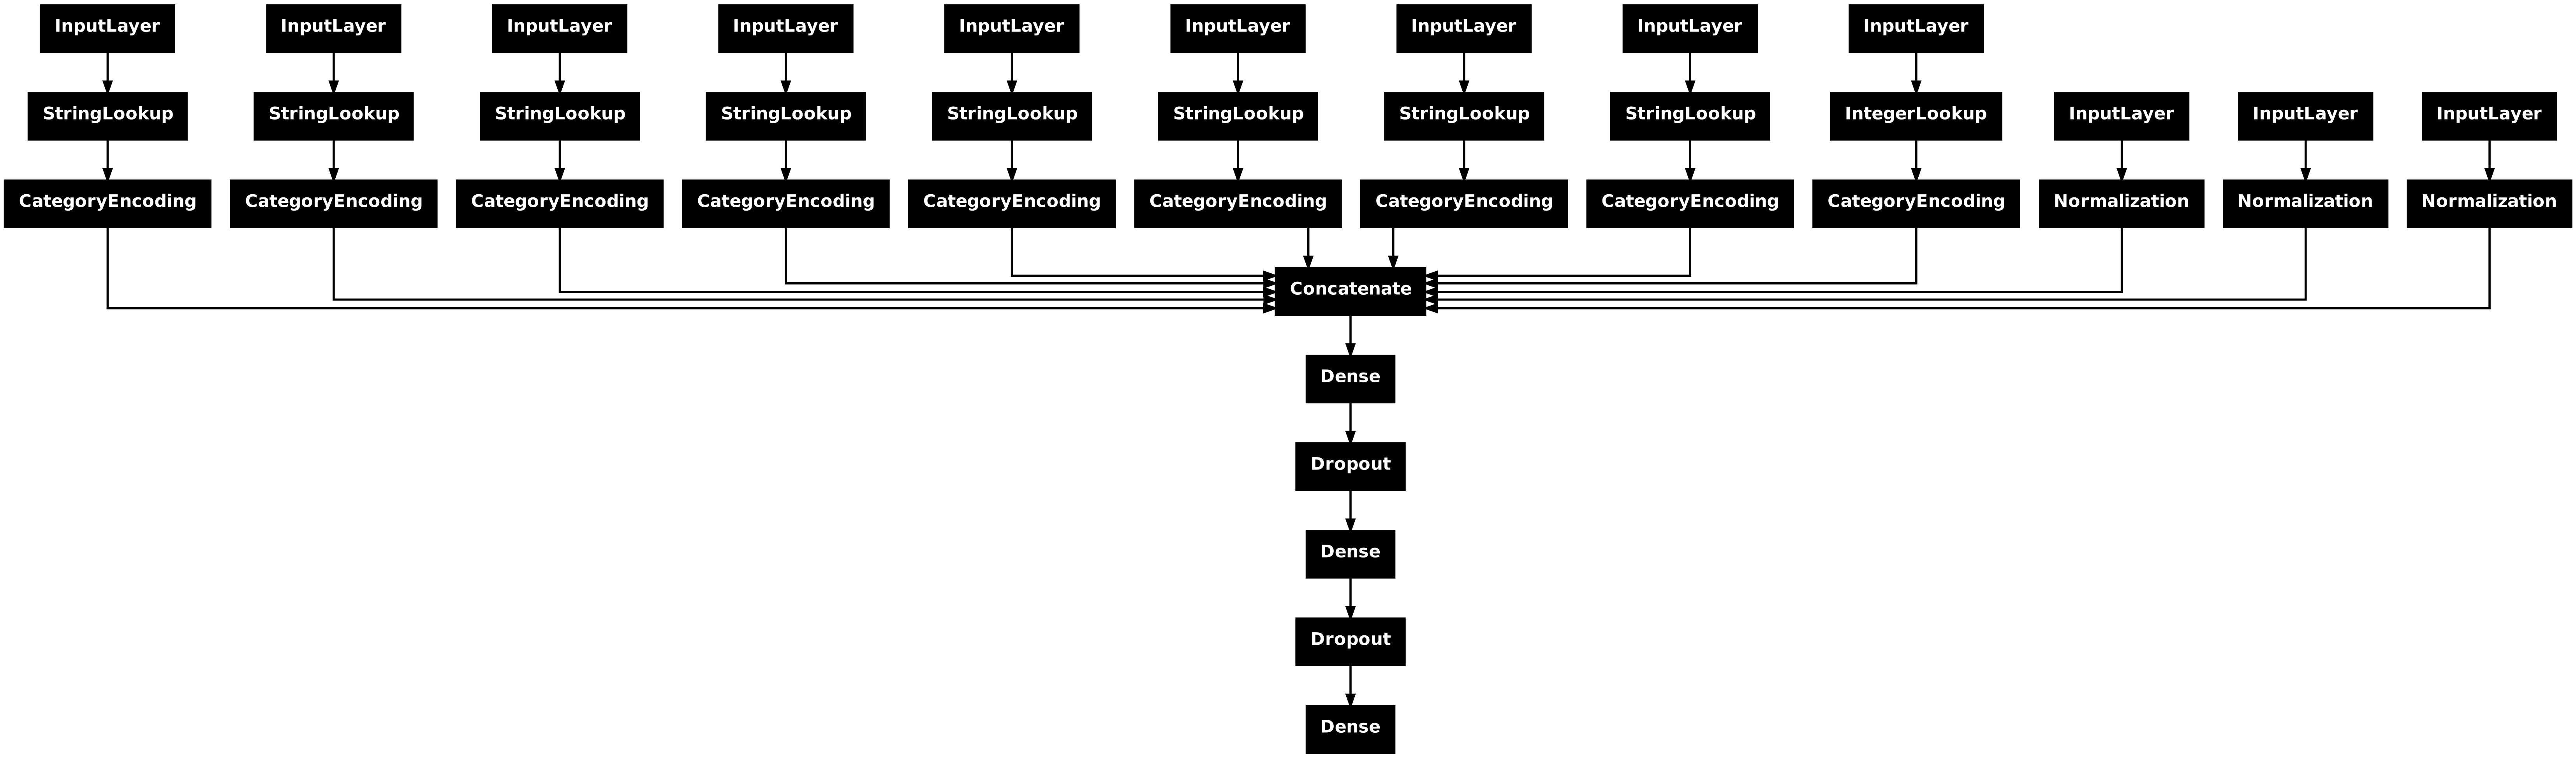

In [12]:
keras.utils.plot_model(model, to_file='model.png')

---
# 4 žingsnis. Mokymas ir įvertinimas

## Mokymas 🏃‍♂️

30 epochų: kiekvienoje epochoje tinklas vieną kartą pamato visą mokymo aibę. Po kiekvienos epochos parodomas
tikslumas su mokymo (`accuracy`) ir validavimo (`val_accuracy`) aibėmis.

In [13]:
history = model.fit(train_ds, validation_data=validation_ds, epochs=30)

Epoch 1/30


.../site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


 1/23 ━━━━━━━━━━━━━━━━━━━━ 32s 1s/step - accuracy: 0.7305 - loss: 0.6863

17/23 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7312 - loss: 0.6250

23/23 ━━━━━━━━━━━━━━━━━━━━ 2s 18ms/step - accuracy: 0.7311 - loss: 0.6097 - val_accuracy: 0.7358 - val_loss: 0.5221


...

23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7797 - loss: 0.4308 - val_accuracy: 0.7997 - val_loss: 0.4127


Epoch 30/30


 1/23 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step - accuracy: 0.7852 - loss: 0.4253

15/23 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7885 - loss: 0.4251 

23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.7824 - loss: 0.4290 - val_accuracy: 0.8026 - val_loss: 0.4114


Mokymo kreivės (originale jas rodė tik TensorBoard). Jei validavimo nuostolis pradėtų kilti, kai mokymo
nuostolis dar krenta, tai reikštų persimokymą.

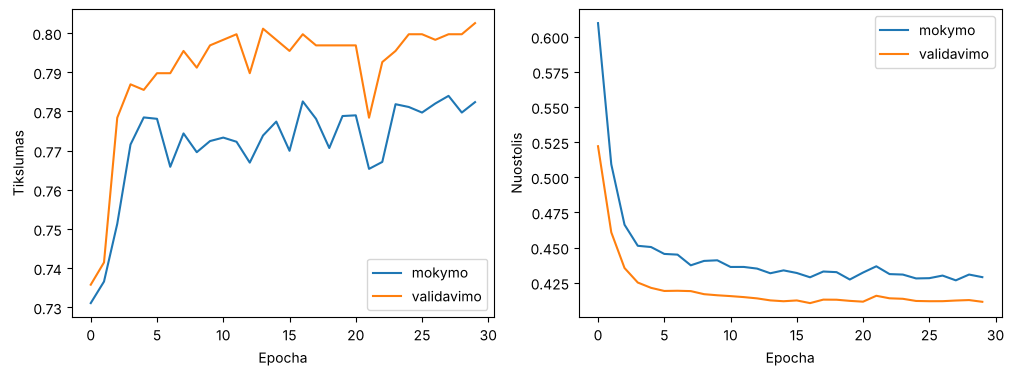

In [14]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='mokymo')
plt.plot(history.history['val_accuracy'], label='validavimo')
plt.xlabel('Epocha'); plt.ylabel('Tikslumas'); plt.legend()
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='mokymo')
plt.plot(history.history['val_loss'], label='validavimo')
plt.xlabel('Epocha'); plt.ylabel('Nuostolis'); plt.legend()
plt.show()

**Ką rodo grafikas:** po ~5 epochų tikslumas beveik nebekyla, o validavimo nuostolis nekyla, todėl persimokymo nėra.
Mokymo tikslumas *žemesnis* už validavimo tikslumą, nes mokymo metu veikia `Dropout` (dalis neuronų išjungta),
o validuojant naudojami visi neuronai. Be to, mokymo tikslumas yra visos epochos vidurkis, o validavimo
tikslumas matuojamas epochos pabaigoje, kai tinklas jau šiek tiek geresnis.

## Įvertinimas ⚖️

In [15]:
loss, accuracy = model.evaluate(test_ds)
print('Tikslumas:     {:.4f}'.format(accuracy))
print('Bazinis lygis: {:.4f}'.format(baseline))

1/3 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.7930 - loss: 0.4424

3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.8085 - loss: 0.4139 


Tikslumas:     0.8085
Bazinis lygis: 0.7574


Klaidų matrica, kaip ir sprendimų miško sąsiuvinyje: kiek išėjusių klientų tinklas atpažino.

In [16]:
logits = model.predict(test_ds, verbose=0)
pred = (tf.nn.sigmoid(logits).numpy().ravel() >= 0.5).astype(int)
cm = pd.crosstab(test['target'].to_numpy(), pred, rownames=['Tikrovė (1 = išėjo)'], colnames=['Prognozė (1 = išeis)'])
print(cm)
print()
print('Atpažinta išėjusių klientų: {} iš {} ({:.0%})'.format(cm.loc[1, 1], cm.loc[1].sum(), cm.loc[1, 1] / cm.loc[1].sum()))

Prognozė (1 = išeis)    0   1
Tikrovė (1 = išėjo)          
0                     470  64
1                      86  85

Atpažinta išėjusių klientų: 85 iš 171 (50%)


---
# 5 žingsnis. Prognozavimas su naujais duomenimis 🛠

## Išsaugome 💾

In [17]:
model.save('Telco_NNModel_L64L32L1.keras')

## Įkeliame ⚙️

In [18]:
reloaded_model = keras.models.load_model('Telco_NNModel_L64L32L1.keras')

## Nauji duomenys 🗃️

Tie patys du išgalvoti klientai kaip sprendimų miško sąsiuvinyje:
* **A**: naujas klientas (2 mėn.), sutartis kas mėnesį, šviesolaidis, elektroninis čekis;
* **B**: ilgametis klientas (4 metai), dvejų metų sutartis, DSL, automatinis pavedimas.

In [19]:
samples = pd.DataFrame([
    {'gender': 'Female', 'SeniorCitizen': 0, 'Partner': 'No', 'Dependents': 'No', 'tenure': 2,
     'PhoneService': 'Yes', 'InternetService': 'Fiber optic', 'Contract': 'Month-to-month',
     'PaperlessBilling': 'Yes', 'PaymentMethod': 'Electronic check',
     'MonthlyCharges': 85.0, 'TotalCharges': 170.0},
    {'gender': 'Male', 'SeniorCitizen': 0, 'Partner': 'Yes', 'Dependents': 'Yes', 'tenure': 48,
     'PhoneService': 'Yes', 'InternetService': 'DSL', 'Contract': 'Two year',
     'PaperlessBilling': 'No', 'PaymentMethod': 'Bank transfer (automatic)',
     'MonthlyCharges': 60.0, 'TotalCharges': 2880.0},
], index=['A', 'B'])
samples

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,InternetService,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges
A,Female,0,No,No,2,Yes,Fiber optic,Month-to-month,Yes,Electronic check,85.0,170.0
B,Male,0,Yes,Yes,48,Yes,DSL,Two year,No,Bank transfer (automatic),60.0,2880.0


## Prognozuojame 🔮

Tinklas grąžina logitą, todėl jį paverčiame tikimybe su `tf.nn.sigmoid`.

In [20]:
input_dict = {name: tf.convert_to_tensor(samples[name].to_numpy()[:, None]) for name in samples.columns}
predictions = reloaded_model.predict(input_dict, verbose=0)
probs = tf.nn.sigmoid(predictions).numpy().ravel()

for name, p in zip(samples.index, probs):
    print('Tikimybė, kad klientas {} išeis: {:.1f} %'.format(name, 100 * p))

Tikimybė, kad klientas A išeis: 75.2 %
Tikimybė, kad klientas B išeis: 1.7 %


---
# TensorBoard

TensorBoard yra TensorFlow įrankis mokymo kreivėms stebėti. `TensorBoard` *callback* kiekvienos epochos pabaigoje
įrašo metrikas į aplanką `logs/fit/...`, o `%tensorboard` atidaro jas interaktyviame lange.

**Dėmesio:** kaip ir originale, čia **tęsiame to paties modelio mokymą** dar 40 epochų (iš viso 70),
o ne mokome naują modelį. Interaktyvus TensorBoard langas matomas tik paleidus sąsiuvinį, išsaugotame faile jo nėra.

In [21]:
%pip install -q tensorboard
%load_ext tensorboard
import datetime

Note: you may need to restart the kernel to use updated packages.


In [22]:
# Ištriname ankstesnių paleidimų žurnalus
!rm -rf ./logs/

In [23]:
log_dir = 'logs/fit/' + datetime.datetime.now().strftime('%Y%m%d-%H%M%S')
tensorboard_callback = keras.callbacks.TensorBoard(log_dir=log_dir, histogram_freq=0)

history_tb = model.fit(train_ds, epochs=40, validation_data=validation_ds, callbacks=[tensorboard_callback], verbose=0)
print('Po 70 epochų: mokymo tikslumas {:.4f}, validavimo tikslumas {:.4f}'.format(
    history_tb.history['accuracy'][-1], history_tb.history['val_accuracy'][-1]))

.../site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


Po 70 epochų: mokymo tikslumas 0.7794, validavimo tikslumas 0.7940


In [24]:
%tensorboard --logdir logs/fit

---
# Išvados

Abu 1.3 sąsiuviniai naudoja tą patį sumaišymą (`random_state=42`), todėl jų **testavimo aibė ta pati** (705 klientai),
ir rezultatus galima lyginti tiesiogiai:

| | Sprendimų miškas | Neuroninis tinklas |
|---|---|---|
| Testavimo tikslumas | 79,3 % | **80,9 %** |
| Bazinis lygis (visada „lieka“) | 75,7 % | 75,7 % |
| Atpažinta išėjusių klientų | 81 iš 171 (47 %) | 85 iš 171 (50 %) |
| Klientas A / klientas B | 88 % / 5 % | 75 % / 2 % |
| Mokymo duomenys | 90 % (6 338) | 80 % (5 634), nes 10 % atiduota validavimui |

1. Tinklas šiame padalijime šiek tiek tikslesnis, bet skirtumas yra apie 11 klientų iš 705. To per mažai,
   kad galėtume teigti, jog tinklas iš tikrųjų geresnis: kitu atsitiktiniu padalijimu rezultatas galėtų būti atvirkščias.
2. Abu modeliai lenkia bazinį lygį ir abu atpažįsta tik apie pusę išeinančių klientų. Ribą nustato duomenys, o ne modelio tipas.
3. Abu modeliai klientą A laiko rizikingu, o klientą B saugiu. Jie išmoko tą pačią logiką.
4. Sprendimų miškui reikėjo daug mažiau darbo: jis pats tvarko tekstinius stulpelius, o tinklui kiekvienam stulpeliui
   reikėjo kodavimo sluoksnio. Be to, mišką lengviau paaiškinti (medis, požymių svarba).
5. Papildomos 40 epochų TensorBoard skyriuje rezultato nepagerino (validavimo tikslumas po 70 epochų 79,4 %):
   tinklas išmoko viską, ką galėjo, per pirmąsias kelias epochas.
6. Originale tinklas pasiekė apie 75 %, o miškas apie 81 %. Ten bazinis lygis buvo apie 50 %, todėl skaičių
   tiesiogiai lyginti su šiais negalima.